# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/damiannogueira/flyrank-ml-intership/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

### Research question

Can pre-decision search-performance signals be used to rank already-visible content for human review more effectively than a simple transparent rule, without overstating what the model can predict?

### Decision supported

The practical decision is not whether a page should be automatically changed. It is which pages an SEO or content team should review first when the portfolio is too large to inspect manually in full.

The project therefore focuses on ranking and prioritization rather than automatic intervention. A useful system should make the review order more informative while keeping the reason for each recommendation understandable to a human reviewer.

The final decision-support workflow compares a simple visibility-based baseline with Logistic Regression, validates the model using a client-grouped split, audits leakage, and converts the validated evidence into a human-reviewed content action playbook.

In [1]:
# Record the capstone question and the practical decision it supports.

research_frame = {
    "research_question": (
        "Can pre-decision search-performance signals be used to rank "
        "already-visible content for human review more effectively than "
        "a simple transparent rule?"
    ),
    "decision_supported": (
        "Prioritize which pages an SEO or content team should review first."
    ),
    "automation_scope": "human decision-support only",
}

research_frame

{'research_question': 'Can pre-decision search-performance signals be used to rank already-visible content for human review more effectively than a simple transparent rule?',
 'decision_supported': 'Prioritize which pages an SEO or content team should review first.',
 'automation_scope': 'human decision-support only'}

## 2. Data

### Source and release

This project uses the **FlyRank ML Internship warehouse**, release `v20260703`.

The main source table is `fact_content_daily_performance`, a pseudonymized daily search-performance table containing **78,835,655 rows** across the full warehouse release. Its original grain is approximately one row per report date, client, and content item.

The capstone does not train directly on 78 million individual rows. I queried the warehouse remotely and aggregated the relevant March 2026 daily observations into one row per client/content item for modeling and evaluation.

### Development windows

The analysis uses the March 2026 development partition.

The **pre-decision window** is:

- March 1–21, 2026.

Only information available during this period is used to create model inputs:

- `impressions_21d`
- `clicks_21d`
- `ctr_21d`
- `avg_position_21d`
- `active_days_21d`

The **future outcome window** is:

- March 22–31, 2026.

This later period is used only to define and evaluate the future decline outcome. It is not used as model input.

### Exclusions

Rows are restricted to observations where GSC data is available. Content items with zero pre-decision impressions are excluded because the search-performance features used by this lane are not meaningful without observed search visibility.

For model development and validation, a page also needs observations in the future outcome window so that its future outcome can be measured. The resulting modeling frame contains **145,091 content items**.

The later action-playbook queue does not require future observations, because an operational recommendation should depend only on information available at the decision point.

Client and content identifiers are pseudonymized and are used only for grouping, joining, deterministic ordering, and validation. They are never model features.

No client names, page URLs, or raw search queries are included in this analysis or public paper.

In [2]:
# Summarize the public-safe data contract used by the capstone.

import pandas as pd

data_contract = pd.DataFrame(
    [
        {
            "item": "Warehouse release",
            "value": "v20260703",
        },
        {
            "item": "Source table",
            "value": "fact_content_daily_performance",
        },
        {
            "item": "Full source rows",
            "value": "78,835,655",
        },
        {
            "item": "Development partition",
            "value": "March 2026",
        },
        {
            "item": "Pre-decision window",
            "value": "2026-03-01 to 2026-03-21",
        },
        {
            "item": "Future outcome window",
            "value": "2026-03-22 to 2026-03-31",
        },
        {
            "item": "Modeling frame",
            "value": "145,091 content items",
        },
        {
            "item": "Availability filter",
            "value": "gsc_data_available = TRUE",
        },
        {
            "item": "Identifier policy",
            "value": "Pseudonymized IDs for grouping/joining only",
        },
    ]
)

data_contract

,item,value
0,Warehouse release,v20260703
1,Source table,fact_content_daily_performance
2,Full source rows,"78,835,655"
3,Development partition,March 2026
4,Pre-decision window,2026-03-01 to 2026-03-21
5,Future outcome window,2026-03-22 to 2026-03-31
6,Modeling frame,"145,091 content items"
7,Availability filter,gsc_data_available = TRUE
8,Identifier policy,Pseudonymized IDs for grouping/joining only


## 3. Methodology

### Prediction point and assumptions

The decision point is the end of March 21, 2026. All model inputs are therefore computed only from March 1–21. Information from March 22 onward is treated as future outcome data and is never used as a valid model feature.

The task is framed as ranking content for review rather than estimating the causal effect of an intervention.

### Features

The final Logistic Regression model uses five pre-decision search-performance features:

- `impressions_21d`
- `clicks_21d`
- `ctr_21d`
- `avg_position_21d`
- `active_days_21d`

Client and content identifiers are used for grouping and joins only and are never supplied to the model.

### Outcome definition

The future outcome compares average daily search impressions in the March 22–31 window with average daily impressions in the March 1–21 window.

A content item receives `future_decline_target = 1` when its future daily impression rate is more than **20% lower** than its pre-decision daily rate.

This threshold is an operational target definition for this study; it should not be interpreted as a universal definition of poor content performance.

### Transparent baseline

Before training a model, I created a simple review rule.

A page qualifies when:

- it has at least **500 pre-decision impressions**; and
- its weighted average search position is at least **4 and below 20**.

Qualifying pages are ranked by pre-decision impressions. This provides an interpretable baseline against which the model can be evaluated.

### Model and validation

The model is a pipeline containing `StandardScaler` followed by `LogisticRegression` with `max_iter=1000` and `random_state=42`.

Validation is grouped by `client_hash_id` using `GroupShuffleSplit`. All content belonging to the same client is kept entirely in either training or test data.

The grouped split produced:

- **136,239 training rows across 35 clients**
- **8,852 test rows across 9 clients**
- **0 overlapping clients**

This design evaluates whether the ranking can transfer to clients that were not represented during model training.

The primary ranking metric is **Precision@50**, because the practical use case is prioritizing a limited number of pages for human review.

### Leakage checks

Every final feature was audited against the prediction timeline. All five inputs are available before the March 21 decision point and none is derived from the future label or an existing product-decision flag.

As a sensitivity test, I deliberately added `future_change_pct`, a variable that directly contributes to the future target definition. Grouped Precision@50 then increased from **28.0% to 100.0%**.

That 100% result is not valid model performance. It demonstrates that the validation setup is sensitive to outcome leakage. The leaky variable was removed, and the final model retains only the five pre-decision features.

In [3]:
# Summarize the final model inputs and validation design.

feature_contract = pd.DataFrame(
    [
        {
            "feature": "impressions_21d",
            "window": "2026-03-01 to 2026-03-21",
            "role": "Pre-decision feature",
        },
        {
            "feature": "clicks_21d",
            "window": "2026-03-01 to 2026-03-21",
            "role": "Pre-decision feature",
        },
        {
            "feature": "ctr_21d",
            "window": "2026-03-01 to 2026-03-21",
            "role": "Pre-decision feature",
        },
        {
            "feature": "avg_position_21d",
            "window": "2026-03-01 to 2026-03-21",
            "role": "Pre-decision feature",
        },
        {
            "feature": "active_days_21d",
            "window": "2026-03-01 to 2026-03-21",
            "role": "Pre-decision feature",
        },
        {
            "feature": "future_change_pct",
            "window": "2026-03-22 to 2026-03-31",
            "role": "Outcome-derived — excluded",
        },
    ]
)

validation_design = pd.DataFrame(
    [
        {
            "item": "Model",
            "value": "StandardScaler + LogisticRegression",
        },
        {
            "item": "Split",
            "value": "Client-grouped GroupShuffleSplit",
        },
        {
            "item": "Training rows",
            "value": "136,239",
        },
        {
            "item": "Training clients",
            "value": "35",
        },
        {
            "item": "Test rows",
            "value": "8,852",
        },
        {
            "item": "Test clients",
            "value": "9",
        },
        {
            "item": "Client overlap",
            "value": "0",
        },
        {
            "item": "Primary metric",
            "value": "Precision@50",
        },
        {
            "item": "Deliberate leakage check",
            "value": "28.0% → 100.0% with future_change_pct",
        },
    ]
)

print("Feature contract")
display(feature_contract)

print()
print("Validation design")
validation_design

Feature contract


,feature,window,role
0,impressions_21d,2026-03-01 to 2026-03-21,Pre-decision feature
1,clicks_21d,2026-03-01 to 2026-03-21,Pre-decision feature
2,ctr_21d,2026-03-01 to 2026-03-21,Pre-decision feature
3,avg_position_21d,2026-03-01 to 2026-03-21,Pre-decision feature
4,active_days_21d,2026-03-01 to 2026-03-21,Pre-decision feature
5,future_change_pct,2026-03-22 to 2026-03-31,Outcome-derived — excluded



Validation design


,item,value
0,Model,StandardScaler + LogisticRegression
1,Split,Client-grouped GroupShuffleSplit
2,Training rows,"136,239"
3,Training clients,35
4,Test rows,"8,852"
5,Test clients,9
6,Client overlap,0
7,Primary metric,Precision@50
8,Deliberate leakage check,28.0% → 100.0% with future_change_pct


## 4. Results (vs baseline)

### Model versus transparent baseline

On the same client-grouped held-out evaluation, the transparent Week-4 rule achieved **20.0% Precision@50**, while Logistic Regression achieved **28.0% Precision@50**.

The grouped test set had a **29.9% positive base rate**.

The model therefore improved on the transparent rule by **8 percentage points**, but it did not exceed the positive base rate of the held-out test population.

This result supports a narrow claim: Logistic Regression ranked the top 50 pages better than the manual rule in this evaluation. It does not support a broader claim that the model reliably identifies future decline across unseen clients.

### Validation design matters

The same Logistic Regression model produced **46.0% Precision@50** under a random row-level split, compared with **28.0%** under the client-grouped split.

The random split contained pages from **40 clients in both training and test data**, while the grouped split had **0 overlapping clients**.

The 18-point difference indicates that the random split answered an easier question. The grouped result is the more defensible estimate for the intended use case because it measures transfer to clients that were not represented during training.

### Practical interpretation

The model result is therefore mixed.

It improves on the simple baseline, but it does not establish enough evidence for automatic content intervention. The useful output is a decision-support ranking that can help prioritize human review while keeping the model's limitations visible.

In [4]:
# Summarize the honest evaluation results used in the paper.

results_table = pd.DataFrame(
    [
        {
            "method": "Transparent baseline",
            "precision_at_50_pct": 20.0,
        },
        {
            "method": "Logistic Regression",
            "precision_at_50_pct": 28.0,
        },
        {
            "method": "Grouped test base rate",
            "precision_at_50_pct": 29.9,
        },
    ]
)

validation_comparison = pd.DataFrame(
    [
        {
            "validation_design": "Random row split",
            "client_overlap": 40,
            "precision_at_50_pct": 46.0,
        },
        {
            "validation_design": "Client-grouped split",
            "client_overlap": 0,
            "precision_at_50_pct": 28.0,
        },
    ]
)

print("Model vs baseline")
display(results_table)

print()
print("Validation comparison")
validation_comparison

Model vs baseline


,method,precision_at_50_pct
0,Transparent baseline,20.0
1,Logistic Regression,28.0
2,Grouped test base rate,29.9



Validation comparison


,validation_design,client_overlap,precision_at_50_pct
0,Random row split,40,46.0
1,Client-grouped split,0,28.0


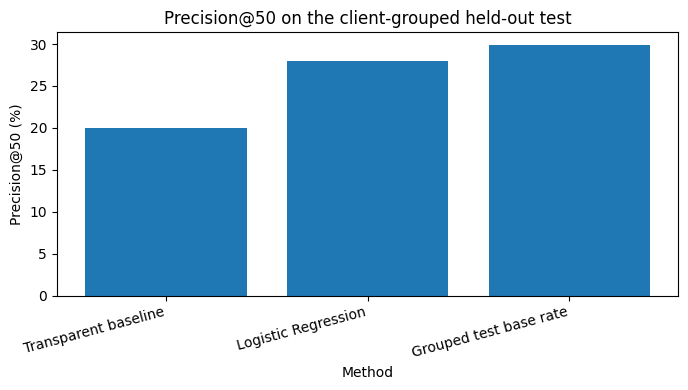

In [5]:
# Visualize the main held-out result for the paper.

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))

ax.bar(
    results_table["method"],
    results_table["precision_at_50_pct"],
)

ax.set_title("Precision@50 on the client-grouped held-out test")
ax.set_ylabel("Precision@50 (%)")
ax.set_xlabel("Method")

plt.xticks(rotation=15, ha="right")

fig.tight_layout()
plt.show()

## 5. Limitations

### Predictive evidence is limited

The Logistic Regression model improved on the transparent rule at Precision@50, but its **28.0%** grouped-test result did not exceed the **29.9%** positive base rate.

The result should therefore be interpreted as mixed evidence, not as proof of reliable decline prediction across unseen clients.

### No causal intervention was tested

This study observes search-performance patterns and evaluates a ranking model. It does not run a controlled content-refresh experiment.

The analysis therefore cannot establish that refreshing a page, changing metadata, or taking another recommended action will cause search performance to improve.

### One development period

The capstone develops and evaluates the current workflow using March 2026 data.

Client-grouped validation reduces same-client leakage, but it does not establish long-term temporal stability. Search behavior, portfolio composition, or measurement conditions may change in later periods.

The current thresholds and ranking logic should therefore be re-audited before being transferred unchanged to another period or portfolio.

### Operational target definition

The `future_decline_target` defines decline as a future daily impression rate more than 20% below the pre-decision daily rate.

This threshold is a practical study definition, not a universal boundary between healthy and unhealthy content.

### Metric scope

Precision@50 was selected because the decision being supported is a limited review queue.

The evaluation does not establish performance for other objectives such as identifying every declining page, maximizing traffic, increasing revenue, improving conversion, or predicting exact future rankings.

### Missing human context

The model features capture observed search visibility and engagement signals, but they do not encode the full editorial or business context of a page.

They cannot determine factual accuracy, brand importance, legal constraints, commercial value, search-result layout, or whether a lower-performing page intentionally serves a narrow purpose.

For these reasons, the final output remains a **human-reviewed decision-support tool**, not an automated content-action system.

In [6]:
# Make the main evidence limits explicit and reusable.

limitations = pd.DataFrame(
    [
        {
            "limitation": "Predictive strength",
            "evidence": "28.0% grouped Precision@50 vs 29.9% base rate",
            "implication": "Do not claim reliable automatic decline prediction",
        },
        {
            "limitation": "Causality",
            "evidence": "No controlled content intervention",
            "implication": "Do not claim recommended actions cause improvement",
        },
        {
            "limitation": "Temporal coverage",
            "evidence": "Development and evaluation use March 2026",
            "implication": "Re-audit before reuse in another period",
        },
        {
            "limitation": "Target definition",
            "evidence": "Decline threshold set at more than 20%",
            "implication": "Treat the label as an operational study definition",
        },
        {
            "limitation": "Metric scope",
            "evidence": "Primary metric is Precision@50",
            "implication": "Results apply to limited review prioritization",
        },
        {
            "limitation": "Human context",
            "evidence": "Five search-performance features only",
            "implication": "Require editorial and business review before action",
        },
    ]
)

limitations

,limitation,evidence,implication
0,Predictive strength,28.0% grouped Precision@50 vs 29.9% base rate,Do not claim reliable automatic decline predic...
1,Causality,No controlled content intervention,Do not claim recommended actions cause improve...
2,Temporal coverage,Development and evaluation use March 2026,Re-audit before reuse in another period
3,Target definition,Decline threshold set at more than 20%,Treat the label as an operational study defini...
4,Metric scope,Primary metric is Precision@50,Results apply to limited review prioritization
5,Human context,Five search-performance features only,Require editorial and business review before a...


## 6. Ranked recommendations

The final output is a human-reviewed content action playbook rather than an automated intervention system.

The playbook contains **28,474 pages** selected using only information available in the March 1–21 pre-decision window.

Pages are prioritized by existing search visibility, measured through pre-decision impressions. This priority represents review opportunity, not predicted uplift or decline probability.

### `PAGE_ONE_VISIBLE`

**20,916 pages**

These pages have at least 500 pre-decision impressions and a weighted average search position from 4 to below 10.

- Reason code: `page_one_visible`
- Review action: `REVIEW_CLICK_CAPTURE`

The page already has meaningful page-one visibility. A reviewer should first inspect search intent, title and description alignment, click capture, and whether the page accurately delivers on the promise shown in search results.

### `STRIKING_DISTANCE`

**7,558 pages**

These pages have at least 500 pre-decision impressions and a weighted average search position from 10 to below 20.

- Reason code: `striking_distance_visible`
- Review action: `REVIEW_REFRESH`

The page has measurable search demand and is close to page one. A reviewer can inspect freshness, topical coverage, internal linking, and whether the content still matches current search intent.

### Human-review rule

The reason code explains why a page appears in the queue; it does not prescribe a mandatory edit.

No page should be automatically rewritten, published, deleted, redirected, or changed solely because of its archetype or rank.

The final decision can also be **no action** when human review shows that the page is already appropriate for its purpose.

In [7]:
# Summarize the final action playbook used by the paper.

recommendations = pd.DataFrame(
    [
        {
            "archetype": "PAGE_ONE_VISIBLE",
            "pages": 20916,
            "reason_code": "page_one_visible",
            "action": "REVIEW_CLICK_CAPTURE",
            "human_review_focus": (
                "Intent match, title, description, click capture, content promise"
            ),
        },
        {
            "archetype": "STRIKING_DISTANCE",
            "pages": 7558,
            "reason_code": "striking_distance_visible",
            "action": "REVIEW_REFRESH",
            "human_review_focus": (
                "Freshness, topical coverage, internal linking, intent alignment"
            ),
        },
    ]
)

print(f"Total pages in review queue: {recommendations['pages'].sum():,}")
recommendations

Total pages in review queue: 28,474


,archetype,pages,reason_code,action,human_review_focus
0,PAGE_ONE_VISIBLE,20916,page_one_visible,REVIEW_CLICK_CAPTURE,"Intent match, title, description, click captur..."
1,STRIKING_DISTANCE,7558,striking_distance_visible,REVIEW_REFRESH,"Freshness, topical coverage, internal linking,..."


## 7. Artifacts the paper embeds

The deployed paper uses a small set of figures and tables that each support one specific part of the argument.

### Figure 1 — Model versus baseline

This figure compares the transparent baseline, Logistic Regression, and the grouped-test positive base rate using Precision@50.

Its purpose is to show the central result without hiding the reference population: the model improves on the manual rule but does not exceed the grouped-test base rate.

### Figure 2 — Validation design comparison

This figure compares the same Logistic Regression model under a random row-level split and a client-grouped split.

Its purpose is to show why validation design matters. The random split reaches 46.0% Precision@50 with 40 overlapping clients, while the grouped split reaches 28.0% with zero overlap.

### Figure 3 — Human-review queue by archetype

This figure summarizes the final action playbook:

- 20,916 `PAGE_ONE_VISIBLE` pages
- 7,558 `STRIKING_DISTANCE` pages

Its purpose is to connect the modeling work to the practical content-review workflow.

Together, the three figures tell the paper's main story: measured model performance, the effect of honest validation, and the human-reviewed action layer that follows from the evidence.

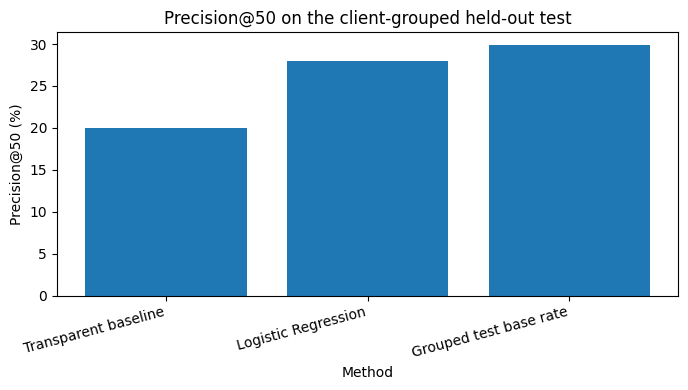

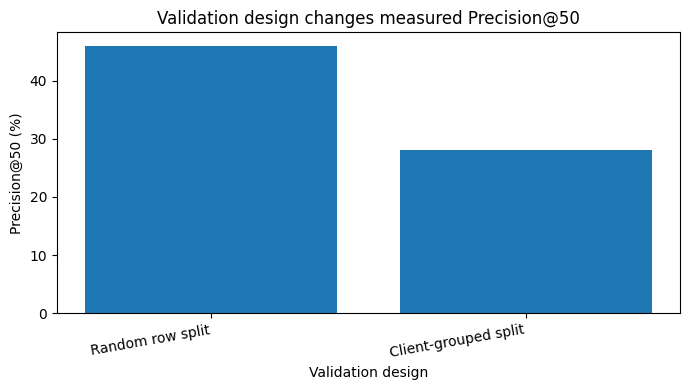

,artifact,path,paper_role
0,Model vs baseline figure,work/figures/capstone_model_vs_baseline.png,Primary result
1,Validation comparison figure,work/figures/capstone_validation_comparison.png,Validation rigor
2,Action queue figure,work/figures/action_queue_archetypes.png,Ranked recommendations


In [8]:
# Export the figures that the deployed research paper will reuse.

from pathlib import Path
import matplotlib.pyplot as plt

FIGURE_DIR = Path("work/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)


# Figure 1: model vs baseline vs grouped-test base rate.
fig1, ax1 = plt.subplots(figsize=(7, 4))

ax1.bar(
    results_table["method"],
    results_table["precision_at_50_pct"],
)

ax1.set_title("Precision@50 on the client-grouped held-out test")
ax1.set_xlabel("Method")
ax1.set_ylabel("Precision@50 (%)")

plt.setp(ax1.get_xticklabels(), rotation=15, ha="right")

fig1.tight_layout()

result_figure_path = FIGURE_DIR / "capstone_model_vs_baseline.png"
fig1.savefig(result_figure_path, dpi=150, bbox_inches="tight")

plt.show()


# Figure 2: random vs grouped validation.
fig2, ax2 = plt.subplots(figsize=(7, 4))

ax2.bar(
    validation_comparison["validation_design"],
    validation_comparison["precision_at_50_pct"],
)

ax2.set_title("Validation design changes measured Precision@50")
ax2.set_xlabel("Validation design")
ax2.set_ylabel("Precision@50 (%)")

plt.setp(ax2.get_xticklabels(), rotation=10, ha="right")

fig2.tight_layout()

validation_figure_path = FIGURE_DIR / "capstone_validation_comparison.png"
fig2.savefig(validation_figure_path, dpi=150, bbox_inches="tight")

plt.show()


# Figure 3 was generated and committed during ML-10.
action_figure_path = FIGURE_DIR / "action_queue_archetypes.png"


paper_artifacts = pd.DataFrame(
    [
        {
            "artifact": "Model vs baseline figure",
            "path": str(result_figure_path),
            "paper_role": "Primary result",
        },
        {
            "artifact": "Validation comparison figure",
            "path": str(validation_figure_path),
            "paper_role": "Validation rigor",
        },
        {
            "artifact": "Action queue figure",
            "path": str(action_figure_path),
            "paper_role": "Ranked recommendations",
        },
    ]
)

paper_artifacts

## Paper-ready sections

### Proposed title

**Prioritizing Content Review with Search Signals: An Honest Client-Grouped Evaluation and Human-Reviewed Action Playbook**

### Abstract

Content teams working across large portfolios need a practical way to decide which already-visible pages deserve human review first.

Using the FlyRank ML Internship warehouse, a 78,835,655-row pseudonymized search-performance release, I aggregated the March 2026 development period into a 145,091-item modeling frame and evaluated pre-decision search signals against a future decline outcome.

A Logistic Regression model achieved **28.0% Precision@50** on a client-grouped held-out test, compared with **20.0%** for a transparent rule baseline, while the same test population had a **29.9%** positive base rate.

The model therefore improved on the manual baseline but did not provide evidence strong enough to support reliable automated decline prediction, and its measured performance fell from **46.0% to 28.0%** when validation changed from random rows to unseen-client grouping.

The final output is a transparent, human-reviewed content action playbook that prioritizes review opportunities with reason codes and explicit limits rather than automatically changing content.

### Introduction / Problem statement

Large content portfolios create a prioritization problem: an SEO or editorial team cannot inspect every page with the same depth at the same time. The practical question is therefore not simply whether future decline can be predicted, but whether observed search-performance signals can help decide which already-visible pages deserve review first.

This project evaluates that decision-support problem using a transparent rule and a Logistic Regression ranking model. The model is judged against the baseline on the same held-out client groups so that any measured improvement is separated from the easier case of seeing pages from the same clients during both training and testing.

The goal is deliberately narrower than automatic optimization. A useful result should help a human reviewer decide where to investigate first, explain why a page appears in the queue, and remain explicit about cases where the evidence does not justify an intervention.

### Reproducibility

The analysis is organized as a sequence of committed notebooks covering the baseline, model training, validation audit, action playbook, and final capstone.

The final evaluation uses a fixed `random_state=42`, a client-grouped split, pre-decision features from March 1–21, 2026, and a future outcome window from March 22–31, 2026.

The public repository contains the notebooks, aggregate metric receipts, and reusable figures required to inspect the evidence behind the paper. Generated row-level queue CSV files remain outside Git by design and can be recreated by rerunning the corresponding notebook.

Repository:

`https://github.com/damiannogueira/flyrank-ml-intership`

Key notebooks:

- `work/notebooks/w04_baseline_score.ipynb`
- `work/notebooks/w05_model.ipynb`
- `work/notebooks/w06_validation_audit.ipynb`
- `work/notebooks/w07_action_playbook.ipynb`
- `work/notebooks/capstone.ipynb`

### Acknowledgments and data credit

Built on the **FlyRank ML Internship dataset** provided by [FlyRank](https://flyrank.ai/).

The warehouse data used in this project is pseudonymized, and the public analysis does not expose client names, page URLs, or raw search queries.

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [x] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.